In [19]:
from matplotlib import pyplot as plt
import cv2
import numpy as np
import pandas as pd
import alc
import ejercicio3
import ejercicio5

filepath_base = '../template-alumnos/salguero'
np.set_printoptions(precision=3, suppress=True)

In [20]:
puntos= pd.read_csv(f'{filepath_base}/world_img_pts.csv', sep=';')
puntos

,pts,X,Y,Z,u_0,v_0,u_1,v_1,u_2,v_2,u_3,v_3
0,6,-4.0,3,0.0,281,474,255,490,469,581,446,563
1,36,4.0,0,0.0,889,521,1071,577,1147,653,1118,621
2,40,6.5,3,0.1,1139,493,1403,550,1425,625,1396,590
3,41,-5.0,14,0.1,418,385,437,377,627,485,600,466
4,42,-5.0,76,0.1,833,262,997,227,1094,357,1064,331


In [21]:
def mostrar_puntos(archivo, pts, etiquetas, color='yellow'):
    img = cv2.imread(f'{filepath_base}/{archivo}')[:, :, ::-1]  # BGR -> RGB

    plt.figure(figsize=(10, 8))
    plt.imshow(img)
    plt.scatter(pts[:, 0], pts[:, 1], s=60, c=color, edgecolors='black')
    for (u, v), etiqueta in zip(pts, etiquetas):
        plt.text(u + 12, v - 12, f'pt {etiqueta}', color='white', backgroundcolor='black', fontsize=8)
    plt.title(archivo)
    plt.show()


def comparar_puntos_y_mostrar(archivo, pts_originales, pts_proyectados, etiquetas):
    img = cv2.imread(f'{filepath_base}/{archivo}')[:, :, ::-1]  # BGR -> RGB

    plt.figure(figsize=(10, 8))
    plt.imshow(img)
    plt.scatter(pts_originales[:, 0], pts_originales[:, 1], s=30, c='yellow', edgecolors='black', label='Originales', zorder=4)
    plt.scatter(pts_proyectados[:, 0], pts_proyectados[:, 1], s=30, c='red', edgecolors='black', label='Proyectados', zorder=5)
    for (u, v), etiqueta in zip(pts_originales, etiquetas):
        plt.text(u + 12, v - 12, f'pt {etiqueta}', color='white', backgroundcolor='black', fontsize=8)
    plt.title(archivo)
    plt.legend()
    plt.show()


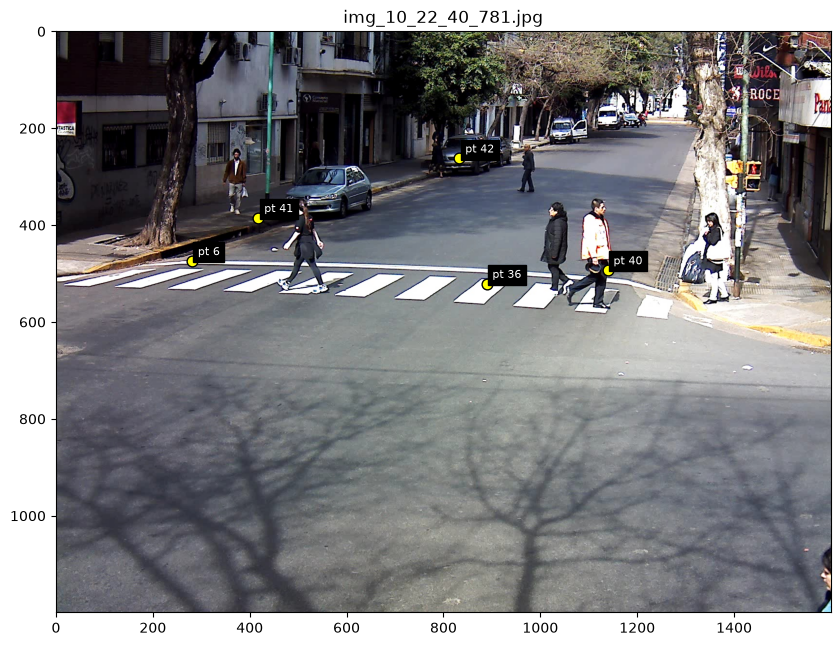

In [22]:
pts_img_list = []
for i in range(4):
    pts_img = puntos[[f'u_{i}', f'v_{i}']]
    pts_img_list.append(pts_img)
pts_img_list = np.array(pts_img_list)

archivos = [
    'img_10_22_40_781.jpg',
    'img_10_23_46_794.jpg',
    'img_10_27_58_713.jpg',
    'img_10_28_40_718.jpg',
]

#for archivo, pts in zip(archivos, pts_img_list):
#    mostrar_puntos(archivo, pts, puntos['pts'])
mostrar_puntos(archivos[0], pts_img_list[0], puntos['pts'])


---

Notar que los puntos $Z$ no son todos $0$, los puntos 2,3 y 4 tienen $Z=0.1$, con lo cual no nos conviene usar el método de Zhang para coplanares. 

Pero tampoco tenemos 6 puntos, que es lo mínimo que precisamos para que con el método de Tsai nos aseguremos una solución única para $Qm=0$ (salvo factor un factor de escala) con $Q\in \R^{2n \times 11}$

In [23]:
pts_3d = puntos[['X', 'Y', 'Z']]
pts_3d

,X,Y,Z
0,-4.0,3,0.0
1,4.0,0,0.0
2,6.5,3,0.1
3,-5.0,14,0.1
4,-5.0,76,0.1


Ninguno de los dos métodos encaja perfectamente a los datos que tenemos para poder encontrar los parámetros extrínsicos y intrínsecos. Lo que podemos hacer es escojer uno, y de alguna forma corregir la solución final para que se aproxime al valor verdadero.

Por simplicidad, escojemos probar con el método de Zhang, asumiendo $Z=0$ para todos los puntos, aprovechando que los $Z$ no nulos estan bastante cerca al $0$ y que tenemos $5>4$ puntos, siendo que para el método de Zhang precisabamos al menos 4 puntos para tambien asegurar una solución única no nula para $Qh=0$, con $Q\in \R^{2n \times 9}$

In [24]:
pts_2d = puntos[['X', 'Y']]
pts_2d

,X,Y
0,-4.0,3
1,4.0,0
2,6.5,3
3,-5.0,14
4,-5.0,76


In [31]:
pts_2d = np.array(puntos[['X', 'Y']])

H_list, K = ejercicio5.obtenerHsK_coplanar(pts_img_list, pts_2d, restringir_K12=False)

R_list = []
t_list = []
for j in range(len(pts_img_list)):
    Rj, tj = ejercicio3.obtenerPose2D(H_list[j], K)
    R_list.append(Rj)
    t_list.append(tj)


Notar que el K obtenido tiene $\gamma = K_{12} \neq 0$ y $K_{11} \neq K_{22}$

In [32]:
print(f"K =\n{K}")

K =
[[2794.805 1246.526  325.524]
 [   0.     228.38   213.433]
 [   0.       0.       1.   ]]


Proyectamos de nuevo los puntos UVW usando la K y las R y t obtenidas para cada vista, para ver el error visualmente

----------------- img_10_22_40_781.jpg -----------------
K =
[[2794.805 1246.526  325.524]
 [   0.     228.38   213.433]
 [   0.       0.       1.   ]]

[R | t] =
[[  0.932   0.356  -0.075 -15.421]
 [  0.004  -0.217  -0.976  39.657]
 [ -0.364   0.909  -0.203  31.091]]

Puntos uv proyectados =
[[ 270.908  465.88 ]
 [ 891.358  519.157]
 [1131.024  496.311]
 [ 397.59   396.187]
 [ 797.999  265.065]]

Puntos uv originales =
[[ 281  474]
 [ 889  521]
 [1139  493]
 [ 418  385]
 [ 833  262]]

Diferencias (en px) = 
[[10.092  8.12 ]
 [ 2.358  1.843]
 [ 7.976  3.311]
 [20.41  11.187]
 [35.001  3.065]]


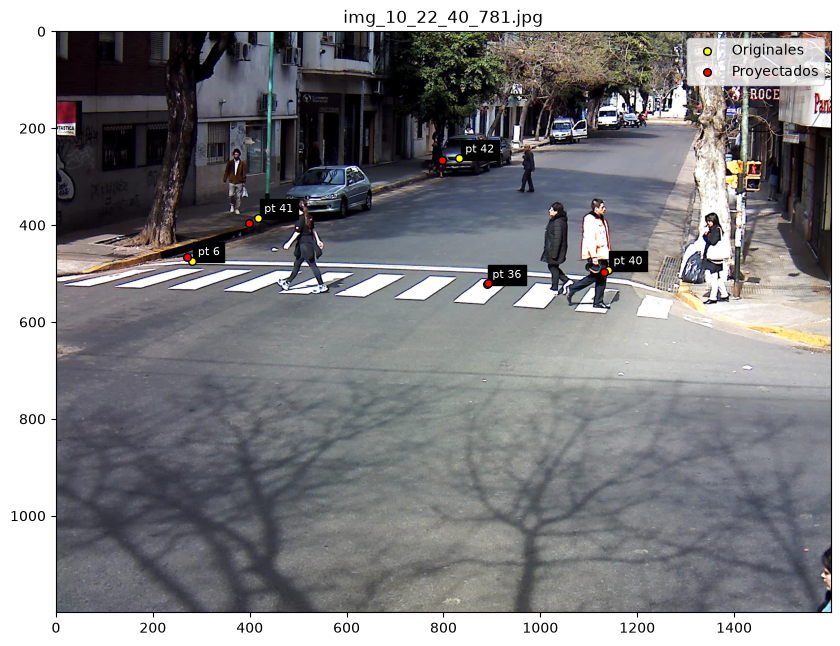

In [33]:
j = 0
pts_3d = np.array(pts_3d)
pts_proyectados = ejercicio5.proyectarPuntosUVW(pts_3d, K, R_list[j], t_list[j])
Rt_j = np.hstack((R_list[j], t_list[j].reshape(-1,1)))

print(f"----------------- {archivos[j]} -----------------")
print(f"K =\n{K}\n")
print(f"[R | t] =\n{Rt_j}\n")
print(f"Puntos uv proyectados =\n{pts_proyectados}\n")
print(f"Puntos uv originales =\n{pts_img_list[j]}\n")
print(f"Diferencias (en px) = \n{np.abs(pts_img_list[j] - pts_proyectados)}")

comparar_puntos_y_mostrar(archivos[j], pts_img_list[j], pts_proyectados, puntos['pts'])

----------------- img_10_23_46_794.jpg -----------------
K =
[[2794.805 1246.526  325.524]
 [   0.     228.38   213.433]
 [   0.       0.       1.   ]]

[R | t] =
[[  0.813   0.502   0.296 -14.072]
 [  0.515  -0.383  -0.767  37.058]
 [ -0.272   0.775  -0.57   25.828]]

Puntos uv proyectados =
[[ 256.655  477.79 ]
 [1074.145  574.521]
 [1410.529  553.255]
 [ 463.429  388.042]
 [1053.03   227.483]]

Puntos uv originales =
[[ 255  490]
 [1071  577]
 [1403  550]
 [ 437  377]
 [ 997  227]]

Diferencias (en px) = 
[[ 1.655 12.21 ]
 [ 3.145  2.479]
 [ 7.529  3.255]
 [26.429 11.042]
 [56.03   0.483]]


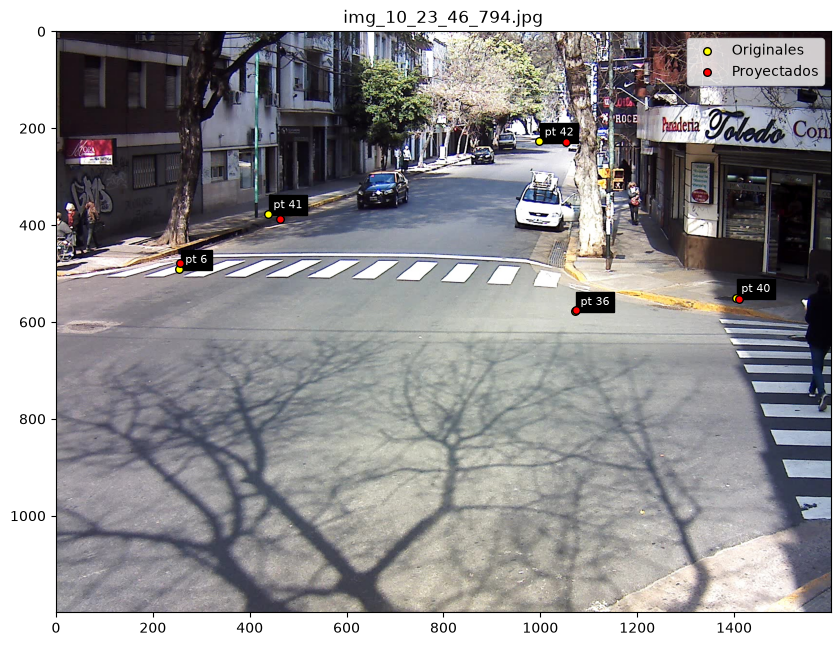

In [34]:
j = 1
pts_3d = np.array(pts_3d)
pts_proyectados = ejercicio5.proyectarPuntosUVW(pts_3d, K, R_list[j], t_list[j])
Rt_j = np.hstack((R_list[j], t_list[j].reshape(-1,1)))

print(f"----------------- {archivos[j]} -----------------")
print(f"K =\n{K}\n")
print(f"[R | t] =\n{Rt_j}\n")
print(f"Puntos uv proyectados =\n{pts_proyectados}\n")
print(f"Puntos uv originales =\n{pts_img_list[j]}\n")
print(f"Diferencias (en px) = \n{np.abs(pts_img_list[j] - pts_proyectados)}")

comparar_puntos_y_mostrar(archivos[j], pts_img_list[j], pts_proyectados, puntos['pts'])

----------------- img_10_27_58_713.jpg -----------------
K =
[[2794.805 1246.526  325.524]
 [   0.     228.38   213.433]
 [   0.       0.       1.   ]]

[R | t] =
[[  0.914   0.31    0.26  -20.063]
 [  0.222   0.154  -0.963  55.372]
 [ -0.339   0.938   0.072  30.822]]

Puntos uv proyectados =
[[ 462.687  572.074]
 [1149.452  649.459]
 [1422.39   628.757]
 [ 622.677  495.191]
 [1088.495  358.374]]

Puntos uv originales =
[[ 469  581]
 [1147  653]
 [1425  625]
 [ 627  485]
 [1094  357]]

Diferencias (en px) = 
[[ 6.313  8.926]
 [ 2.452  3.541]
 [ 2.61   3.757]
 [ 4.323 10.191]
 [ 5.505  1.374]]


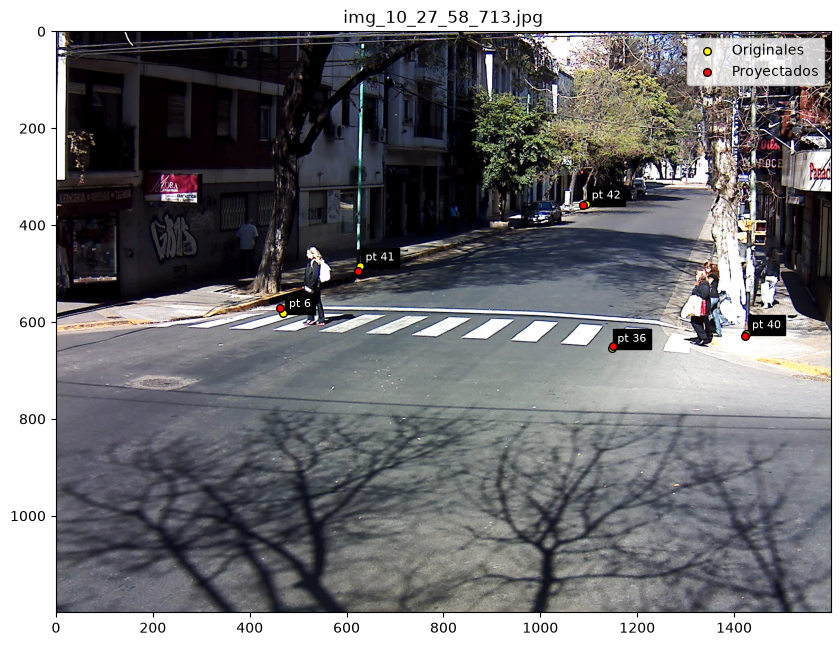

In [35]:
j = 2
pts_3d = np.array(pts_3d)
pts_proyectados = ejercicio5.proyectarPuntosUVW(pts_3d, K, R_list[j], t_list[j])
Rt_j = np.hstack((R_list[j], t_list[j].reshape(-1,1)))

print(f"----------------- {archivos[j]} -----------------")
print(f"K =\n{K}\n")
print(f"[R | t] =\n{Rt_j}\n")
print(f"Puntos uv proyectados =\n{pts_proyectados}\n")
print(f"Puntos uv originales =\n{pts_img_list[j]}\n")
print(f"Diferencias (en px) = \n{np.abs(pts_img_list[j] - pts_proyectados)}")

comparar_puntos_y_mostrar(archivos[j], pts_img_list[j], pts_proyectados, puntos['pts'])

----------------- img_10_28_40_718.jpg -----------------
K =
[[2794.805 1246.526  325.524]
 [   0.     228.38   213.433]
 [   0.       0.       1.   ]]

[R | t] =
[[  0.94    0.342  -0.018 -17.531]
 [ -0.026   0.018  -1.     48.345]
 [ -0.341   0.94    0.025  28.592]]

Puntos uv proyectados =
[[ 442.144  551.399]
 [1120.408  618.084]
 [1384.856  589.925]
 [ 598.091  468.97 ]
 [1037.436  325.068]]

Puntos uv originales =
[[ 446  563]
 [1118  621]
 [1396  590]
 [ 600  466]
 [1064  331]]

Diferencias (en px) = 
[[ 3.856 11.601]
 [ 2.408  2.916]
 [11.144  0.075]
 [ 1.909  2.97 ]
 [26.564  5.932]]


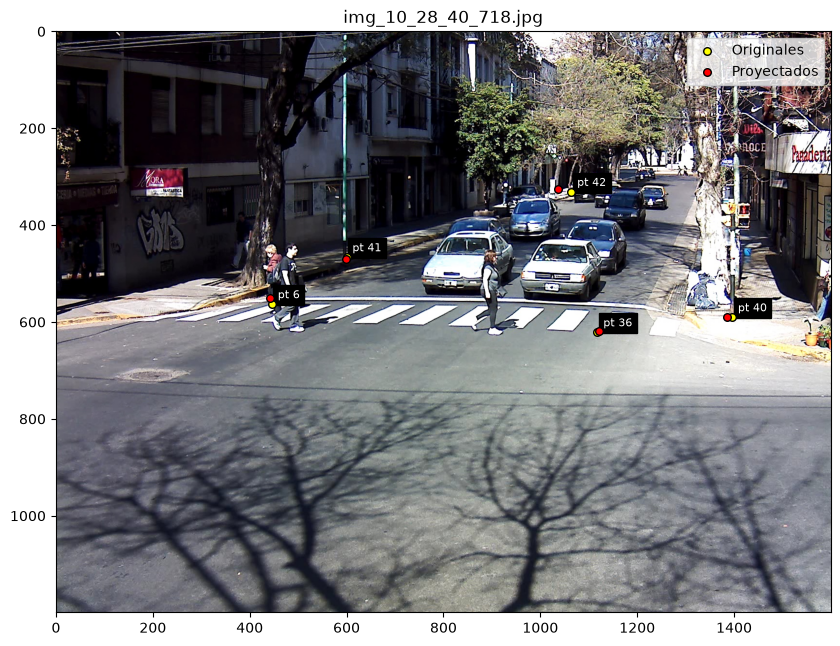

In [36]:
j = 3
pts_3d = np.array(pts_3d)
pts_proyectados = ejercicio5.proyectarPuntosUVW(pts_3d, K, R_list[j], t_list[j])
Rt_j = np.hstack((R_list[j], t_list[j].reshape(-1,1)))

print(f"----------------- {archivos[j]} -----------------")
print(f"K =\n{K}\n")
print(f"[R | t] =\n{Rt_j}\n")
print(f"Puntos uv proyectados =\n{pts_proyectados}\n")
print(f"Puntos uv originales =\n{pts_img_list[j]}\n")
print(f"Diferencias (en px) = \n{np.abs(pts_img_list[j] - pts_proyectados)}")

comparar_puntos_y_mostrar(archivos[j], pts_img_list[j], pts_proyectados, puntos['pts'])

---

# Ejercicio 5b